In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt

# Константы из предыдущих задач
YIELD = 10000 # фотонов/МэВ
L_ATT = 8.0   # длина затухания в метрах
R_DET = 2.0   # радиус детектора
N_PMT = 40    # число ФЭУ
R_PMT = 0.1   # радиус ФЭУ
A_EFF = 0.5   # эффективность

i = np.arange(N_PMT) + 0.5
phi = np.arccos(1 - 2*i/N_PMT)
theta = np.pi * (1 + 5**0.5) * i

x_pmt = R_DET * np.sin(phi) * np.cos(theta)
y_pmt = R_DET * np.sin(phi) * np.sin(theta)
z_pmt = R_DET * np.cos(phi)

pmt_pos = np.stack([x_pmt, y_pmt, z_pmt], axis=1)
E_true = 1.2
pos_true = np.array([0.3, -0.4, 0.5])

def calc_mu_numpy(E, pos):
    vec = pmt_pos - pos
    dist = np.linalg.norm(vec, axis=1)
    
    cos_a = np.sum((pmt_pos/R_PMT) * (vec/dist[:, None]), axis=1)
    cos_a = np.clip(cos_a, 0, None)
    
    omega = (np.pi * R_PMT**2) / (dist**2) * cos_a
    mu = (YIELD * E) * (omega / (4*np.pi)) * A_EFF
    return mu

mu_ideal = calc_mu_numpy(E_true, pos_true)
observed_pe = np.random.poisson(mu_ideal)

print("Истинная энергия:", E_true)
print("Сумма PE:", np.sum(observed_pe))

Истинная энергия: 1.2
Сумма PE: 3006


In [11]:
pmt_pos_t = pt.constant(pmt_pos)

def calc_mu_pymc(E, pos_vec):
    vec = pmt_pos_t - pos_vec
    dist = pt.sqrt(pt.sum(vec**2, axis=1))
    dist = dist + 1e-6
    
    cos_a = pt.sum((pmt_pos_t / R_PMT) * (vec / dist[:, None]), axis=1)
    cos_a = pt.maximum(cos_a, 0)
    
    omega = (np.pi * R_PMT**2) / (dist**2) * cos_a
    mu = (YIELD * E) * (omega / (4*np.pi)) * A_EFF
    return mu

with pm.Model() as model:
    E = pm.Uniform('E', lower=0, upper=3)
    x = pm.Uniform('x', lower=-2, upper=2)
    y = pm.Uniform('y', lower=-2, upper=2)
    z = pm.Uniform('z', lower=-2, upper=2)
    
    pos = pt.stack([x, y, z])
    mu = calc_mu_pymc(E, pos)
    pe_obs = pm.Poisson('pe_obs', mu=mu, observed=observed_pe)

NUTS[nutpie]: [E, x, y, z]


Output()

Энергия (истина / реконструкция): 1.2 1.201032496969765
X (истина / реконструкция): 0.3 0.3385782817068803
Y (истина / реконструкция): -0.4 -0.3401323689044228
Z (истина / реконструкция): 0.5 0.49966476471174515


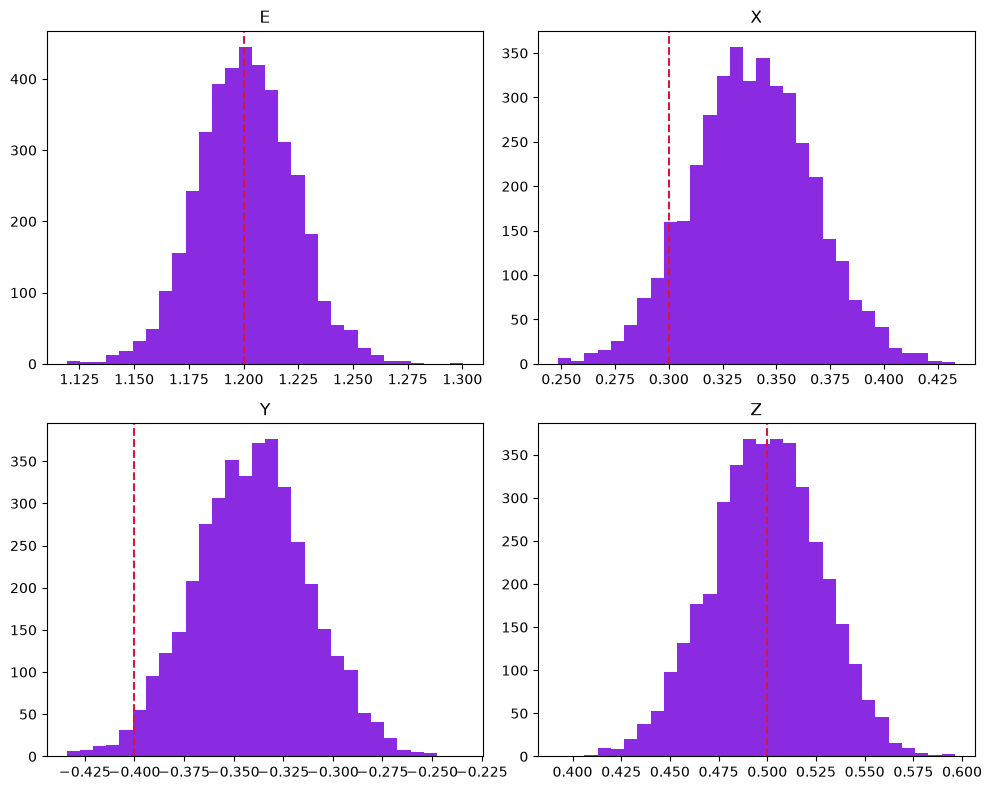

In [12]:
with model:
    trace = pm.sample(1000, tune=500)
    
E_s = trace.posterior['E'].values.flatten()
x_s = trace.posterior['x'].values.flatten()
y_s = trace.posterior['y'].values.flatten()
z_s = trace.posterior['z'].values.flatten()

print("Энергия (истина / реконструкция):", E_true, np.median(E_s))
print("X (истина / реконструкция):", pos_true[0], np.median(x_s))
print("Y (истина / реконструкция):", pos_true[1], np.median(y_s))
print("Z (истина / реконструкция):", pos_true[2], np.median(z_s))

fig, ax = plt.subplots(2, 2, figsize=(10, 8))
ax[0,0].hist(E_s, bins=30, color='blueviolet')
ax[0,0].axvline(E_true, color='crimson', linestyle='--')
ax[0,0].set_title('E')

ax[0,1].hist(x_s, bins=30, color='blueviolet')
ax[0,1].axvline(pos_true[0], color='crimson', linestyle='--')
ax[0,1].set_title('X')

ax[1,0].hist(y_s, bins=30, color='blueviolet')
ax[1,0].axvline(pos_true[1], color='crimson', linestyle='--')
ax[1,0].set_title('Y')

ax[1,1].hist(z_s, bins=30, color='blueviolet')
ax[1,1].axvline(pos_true[2], color='crimson', linestyle='--')
ax[1,1].set_title('Z')
plt.tight_layout()
plt.show()